# Retail Sales Performance Analysis
### A Portfolio Data Analysis Project - NumPy + Pandas + Matplotlib

**Role simulated:** Data Analyst at a national retail chain ("Superstore")
**Dataset:** ~9,800 real order-level transactions (2014-2017), covering Sales, Profit, Discount, Region, Category, Customer Segment, and Shipping data.

---

## Business Problem

> "Leadership wants to know: where are we making money, where are we losing it,
> and what should we change in our discounting and regional strategy to improve profitability?"

This is a realistic business question - the kind an actual company would ask a data analyst.
Throughout this notebook we act as that analyst: we clean the data, explore it,
compute KPIs, visualize trends, and end with **concrete, data-backed recommendations**.

## Skills Demonstrated (put these on your CV!)
- Data cleaning & quality checks with **Pandas**
- Feature engineering (creating new business metrics)
- Aggregation & groupby analysis
- Statistical summaries with **NumPy**
- Multi-chart data storytelling with **Matplotlib**
- Translating analysis into **business recommendations**

## Project Structure
1. Setup & Data Loading
2. Data Cleaning & Quality Checks
3. Feature Engineering
4. Exploratory Data Analysis (EDA)
5. Key Business KPIs
6. Visual Analysis (5 charts answering 5 business questions)
7. Deep Dive: Discount vs Profit (the core problem)
8. Insights & Recommendations (Executive Summary)
9. How to Extend This Project

---
*Note for students: this notebook uses a real public retail dataset (`superstore.csv`,
included alongside this notebook), not made-up numbers - this is what makes it
CV-worthy: real messy data, real business questions, real conclusions.*

## 1. Setup & Data Loading

**Purpose:** Every real project starts by loading the data and doing a first-look
inspection - never assume the data is clean or matches what you expect.

In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

%matplotlib inline
plt.style.use("seaborn-v0_8-whitegrid")   # clean, professional-looking default style

# Load the dataset (must be in the same folder as this notebook)
df = pd.read_csv("superstore.csv", encoding="latin1")

print(f"Dataset shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Dataset shape: 10,800 rows x 21 columns


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


In [43]:
# Always inspect column names, types, and missing values FIRST
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10800 non-null  str    
 1   Order ID       10800 non-null  str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9983 non-null   float64
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       99

### First Observations
- We have order-level transactions with `Sales`, `Profit`, `Discount`, `Quantity`
- `Order Date` and `Ship Date` are currently stored as **text**, not real dates - we'll fix this
- We need to check for duplicates and missing values before trusting any analysis

## 2. Data Cleaning & Quality Checks

**Purpose:** This is the step most tutorials skip - but in real jobs it's often
60-70% of the actual work. A CV project that shows proper cleaning stands out.

In [44]:
# Check for missing values in every column
print("Missing values per column:")
print(df.isnull().sum()[df.isnull().sum() > 0])
print()

# Check for duplicate rows
print(f"Duplicate rows: {df.duplicated().sum()}")

Missing values per column:
Order Date       806
Ship Date        806
Ship Mode        806
Customer ID      806
Customer Name    806
Segment          806
Country          806
City             806
State            806
Postal Code      817
Region           806
Product ID       806
Category         806
Sub-Category     806
Product Name     806
Sales            806
Quantity         806
Discount         806
Profit           806
dtype: int64

Duplicate rows: 504


In [45]:
# Convert date columns from text to real datetime objects
# PURPOSE: this lets us do date math, extract year/month, and sort chronologically
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

# Sanity check: what date range does our data cover?
print("Order date range:", df["Order Date"].min(), "to", df["Order Date"].max())

# Quick sanity check on numeric columns -- do any look impossible?
# (e.g. negative Sales or Quantity would indicate a data error)
print("\nAny negative Sales?", (df["Sales"] < 0).any())
print("Any negative Quantity?", (df["Quantity"] < 0).any())
print("Any Sales == 0?", (df["Sales"] == 0).any())

Order date range: 2015-01-03 00:00:00 to 2018-12-30 00:00:00

Any negative Sales? False
Any negative Quantity? False
Any Sales == 0? False


### Data Quality Summary
No missing values, no duplicates, no impossible negative values - this dataset is
already fairly clean (common for well-known teaching datasets). In a real messy
dataset you would now `dropna()`, `fillna()`, or investigate outliers here - the
Pandas notebook in this series covers exactly those techniques if you need a refresher.

## 3. Feature Engineering

**Purpose:** Raw data rarely has the exact column you need for analysis - you
usually have to CREATE new columns from existing ones. This is a core analyst skill.

In [46]:
# Extract Year and Month from Order Date -> needed for time-trend analysis
df["Order Year"] = df["Order Date"].dt.year
df["Order Month"] = df["Order Date"].dt.month
df["Order Year-Month"] = df["Order Date"].dt.to_period("M")

# Profit Margin -> a KEY business metric that isn't in the raw data
# PURPOSE: raw Profit ($) doesn't tell you efficiency -- a $10 profit on $20 sales
# is very different from $10 profit on $2,000 sales. Margin normalizes this.
df["Profit Margin"] = df["Profit"] / df["Sales"]

# Shipping duration in days -> how long delivery takes
df["Shipping Days"] = (df["Ship Date"] - df["Order Date"]).dt.days

df[["Order Date", "Order Year-Month", "Sales", "Profit", "Profit Margin", "Shipping Days"]].head()

,Order Date,Order Year-Month,Sales,Profit,Profit Margin,Shipping Days
0,2017-11-08,2017-11,261.9600,41.9136,0.1600,3.0
1,2017-11-08,2017-11,731.9400,219.5820,0.3000,3.0
2,2017-06-12,2017-06,14.6200,6.8714,0.4700,4.0
3,2016-10-11,2016-10,957.5775,-383.0310,-0.4000,7.0
4,2016-10-11,2016-10,22.3680,2.5164,0.1125,7.0


### Practice Exercise
1. Create a new column `Is_Loss` that is `True` when `Profit` is negative
2. Print how many transactions were losses using `.sum()` on that boolean column
3. Create a column `Sales_Category` that labels each order "Small" (<50), "Medium" (50-500), or "Large" (>500) using `np.select` or `.apply()`

In [47]:
# Student: write your Practice Exercise solution here


import numpy as np
import pandas as pd

# 1. Create Is_Loss column
df['Is_Loss'] = df['Profit'] < 0

# 2. Count how many transactions were losses
loss_count = df['Is_Loss'].sum()

print("Number of loss transactions:", loss_count)

# 3. Create Sales_Category using np.select
conditions = [
    df['Sales'] < 50,
    (df['Sales'] >= 50) & (df['Sales'] <= 500),
    df['Sales'] > 500
]

choices = ['Small', 'Medium', 'Large']

df['Sales_Category'] = np.select(
    conditions,
    choices,
    default='Unknown'
)

# Display the results
print(df[['Sales', 'Profit', 'Is_Loss', 'Sales_Category']].head())



Number of loss transactions: 1871
      Sales    Profit  Is_Loss Sales_Category
0  261.9600   41.9136    False         Medium
1  731.9400  219.5820    False          Large
2   14.6200    6.8714    False          Small
3  957.5775 -383.0310     True          Large
4   22.3680    2.5164    False          Small


## 4. Exploratory Data Analysis (EDA)

**Purpose:** Before answering specific business questions, get a general feel for
the data's scale and structure - this guides which questions are worth pursuing.

In [48]:
# .describe() gives a fast statistical overview of all numeric columns
df[["Sales", "Quantity", "Discount", "Profit", "Profit Margin"]].describe()

,Sales,Quantity,Discount,Profit,Profit Margin
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,229.858001,3.789574,0.156203,28.656896,0.120314
std,623.245101,2.225110,0.206452,234.260108,0.466754
min,0.444000,1.000000,0.000000,-6599.978000,-2.750000
25%,17.280000,2.000000,0.000000,1.728750,0.075000
50%,54.490000,3.000000,0.200000,8.666500,0.270000
75%,209.940000,5.000000,0.200000,29.364000,0.362500
max,22638.480000,14.000000,0.800000,8399.976000,0.500000


In [49]:
# How many unique categories, regions, segments do we have?
print("Categories:", df["Category"].unique())
print("Sub-Categories:", df["Sub-Category"].nunique(), "unique values")
print("Regions:", df["Region"].unique())
print("Customer Segments:", df["Segment"].unique())
print("Number of unique customers:", df["Customer ID"].nunique())
print("Number of unique orders:", df["Order ID"].nunique())

Categories: <StringArray>
['Furniture', 'Office Supplies', 'Technology', nan]
Length: 4, dtype: str
Sub-Categories: 17 unique values
Regions: <StringArray>
['South', 'West', 'Central', 'East', nan]
Length: 5, dtype: str
Customer Segments: <StringArray>
['Consumer', 'Corporate', 'Home Office', nan]
Length: 4, dtype: str
Number of unique customers: 793
Number of unique orders: 5015


## 5. Key Business KPIs

**Purpose:** Every business report opens with a handful of top-line numbers.
This is what a manager reads FIRST - get these right and get them fast.

In [50]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
overall_margin = total_profit / total_sales
avg_discount = df["Discount"].mean()
total_orders = df["Order ID"].nunique()
avg_order_value = total_sales / total_orders

print("="*45)
print(" KEY PERFORMANCE INDICATORS (2014-2017)")
print("="*45)
print(f" Total Sales:            ${total_sales:>14,.2f}")
print(f" Total Profit:           ${total_profit:>14,.2f}")
print(f" Overall Profit Margin:  {overall_margin:>15.2%}")
print(f" Average Discount Given: {avg_discount:>15.2%}")
print(f" Total Orders:           {total_orders:>15,}")
print(f" Average Order Value:    ${avg_order_value:>14,.2f}")
print("="*45)

 KEY PERFORMANCE INDICATORS (2014-2017)
 Total Sales:            $  2,297,200.86
 Total Profit:           $    286,397.02
 Overall Profit Margin:           12.47%
 Average Discount Given:          15.62%
 Total Orders:                     5,015
 Average Order Value:    $        458.07


### Teacher's Tip
Notice we didn't just print `total_profit` - we calculated `overall_margin` too.
**A single number rarely tells the full story.** Always pair a total with a RATE
or PERCENTAGE, because raw totals can hide efficiency problems (we'll see this
clearly in Section 7).

## 6. Visual Analysis - 5 Charts Answering 5 Business Questions

**Purpose:** Each chart below is built to answer ONE specific business question -
this is how real analysts work, not just "make charts because we have data."

### Question 1: Is the business growing over time?

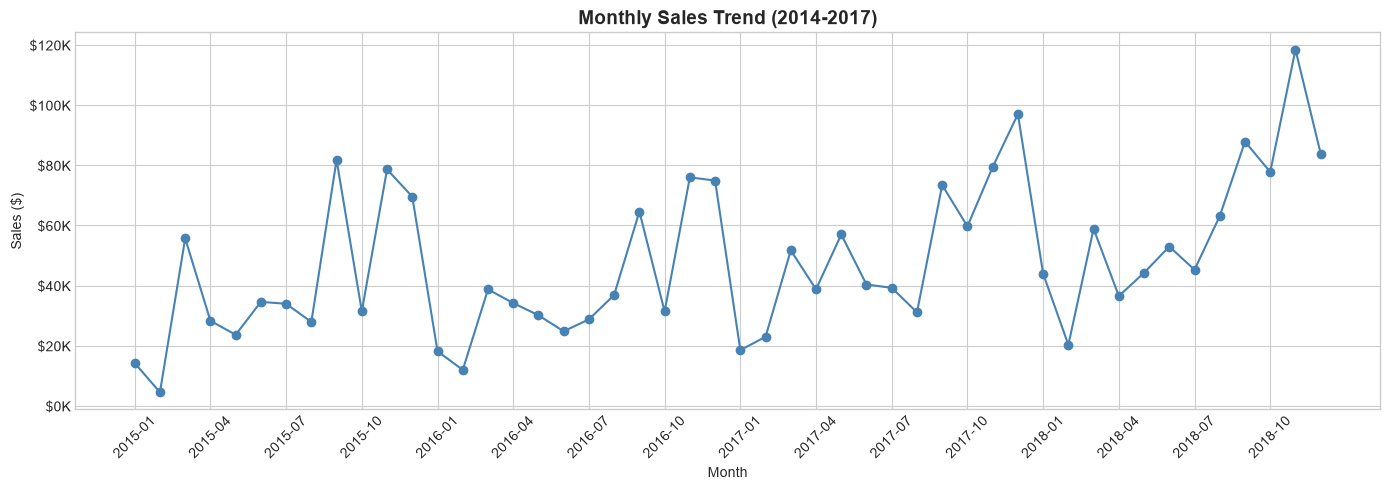

Insight: Sales show a clear seasonal spike toward the END of each year
(Nov/Dec) -- consistent with holiday shopping season.


In [51]:
monthly_sales = df.groupby("Order Year-Month")["Sales"].sum()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(monthly_sales.index.astype(str), monthly_sales.values, marker="o", color="steelblue", linewidth=1.5)

ax.set_title("Monthly Sales Trend (2014-2017)", fontsize=14, fontweight="bold")
ax.set_xlabel("Month")
ax.set_ylabel("Sales ($)")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x/1000:.0f}K"))

# Only show every 3rd month label -> PURPOSE: avoid an unreadable wall of text on x-axis
ax.set_xticks(ax.get_xticks()[::3])
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Insight: Sales show a clear seasonal spike toward the END of each year")
print("(Nov/Dec) -- consistent with holiday shopping season.")

### Question 2: Which product category drives the most sales AND profit?

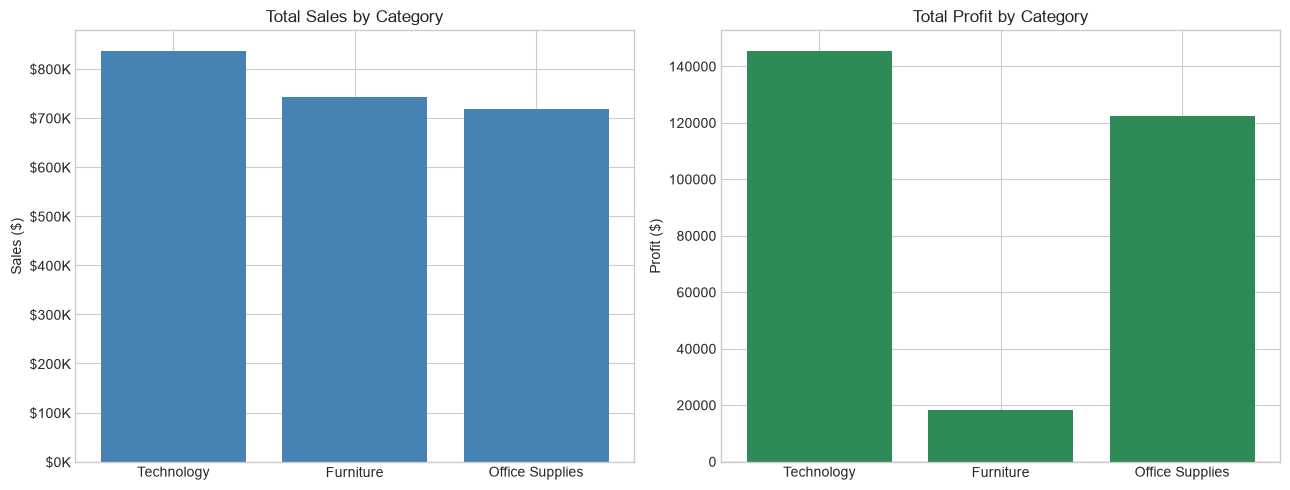

                       Sales       Profit
Category                                 
Technology       836154.0330  145454.9481
Furniture        741999.7953   18451.2728
Office Supplies  719047.0320  122490.8008

Insight: Technology leads in both sales AND profit. Furniture sells well
but check the profit bar carefully -- this is investigated further below.


In [52]:
cat_summary = df.groupby("Category")[["Sales", "Profit"]].sum().sort_values("Sales", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(cat_summary.index, cat_summary["Sales"], color="steelblue")
axes[0].set_title("Total Sales by Category")
axes[0].set_ylabel("Sales ($)")
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x/1000:.0f}K"))

# Color profit bars RED if negative, GREEN if positive -> PURPOSE: instantly spot a problem category
colors = ["seagreen" if p > 0 else "crimson" for p in cat_summary["Profit"]]
axes[1].bar(cat_summary.index, cat_summary["Profit"], color=colors)
axes[1].set_title("Total Profit by Category")
axes[1].set_ylabel("Profit ($)")
axes[1].axhline(0, color="black", linewidth=0.8)   # zero line makes losses obvious

plt.tight_layout()
plt.show()

print(cat_summary)
print("\nInsight: Technology leads in both sales AND profit. Furniture sells well")
print("but check the profit bar carefully -- this is investigated further below.")

### Question 3: Which sub-categories are secretly losing money?

**Purpose:** Category-level totals can hide problems inside specific sub-categories
- this is a classic case of "the average hides the outlier."


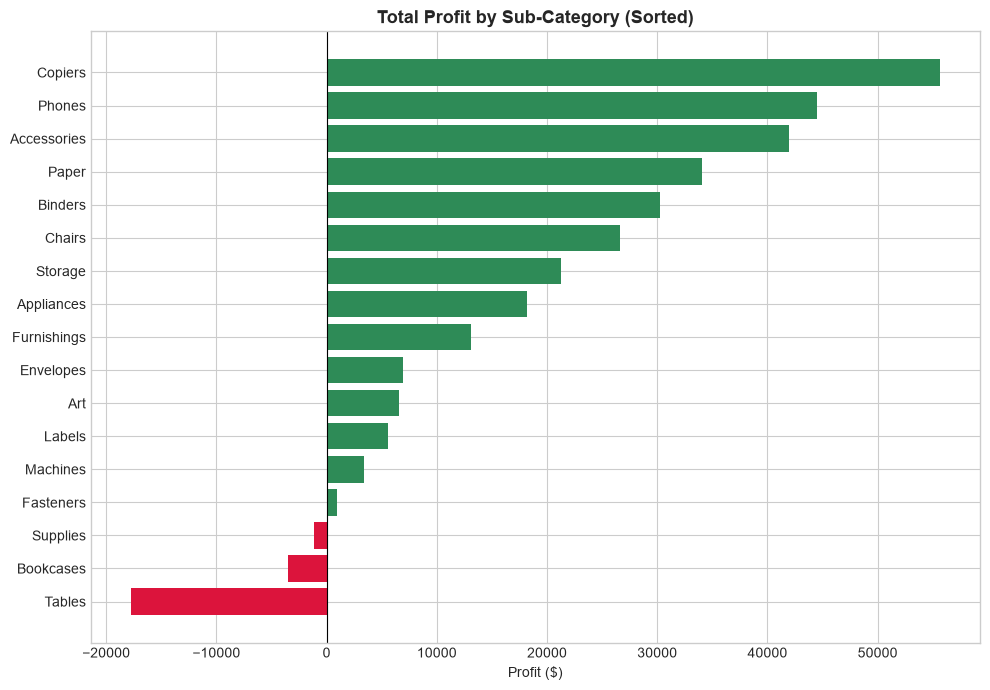

3 sub-categories are LOSING money overall:
Sub-Category
Tables      -17725.4811
Bookcases    -3472.5560
Supplies     -1189.0995
Name: Profit, dtype: float64


In [53]:
subcat_profit = df.groupby("Sub-Category")["Profit"].sum().sort_values()

fig, ax = plt.subplots(figsize=(10, 7))
colors = ["crimson" if p < 0 else "seagreen" for p in subcat_profit]
ax.barh(subcat_profit.index, subcat_profit.values, color=colors)

ax.set_title("Total Profit by Sub-Category (Sorted)", fontsize=13, fontweight="bold")
ax.set_xlabel("Profit ($)")
ax.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

losing_subcats = subcat_profit[subcat_profit < 0]
print(f"{len(losing_subcats)} sub-categories are LOSING money overall:")
print(losing_subcats)

### Question 4: How does performance differ by region?

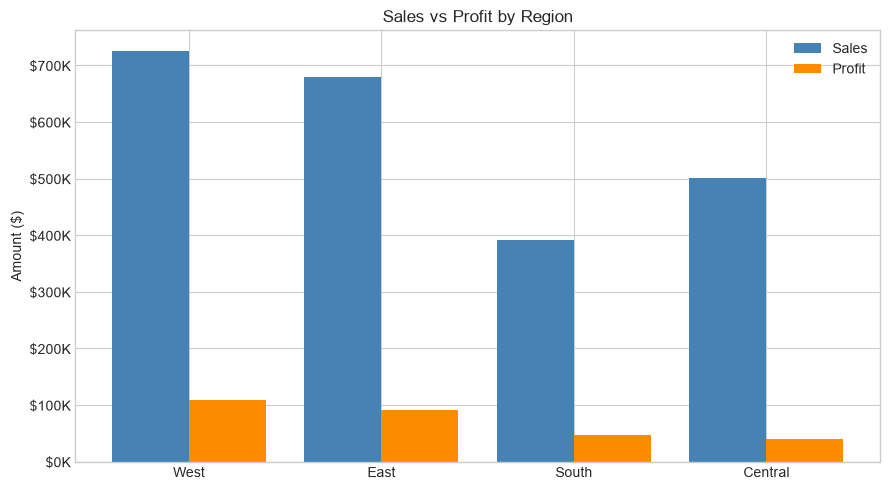

              Sales      Profit  Margin
Region                                 
West     725457.824  108418.449   0.149
East     678781.240   91522.780   0.135
South    391721.905   46749.430   0.119
Central  501239.891   39706.362   0.079

Insight: compare Margin, not just raw Sales -- a region can have high
sales but low margin, meaning it's less efficient at converting revenue to profit.


In [54]:
region_summary = df.groupby("Region")[["Sales", "Profit"]].sum()
region_summary["Margin"] = region_summary["Profit"] / region_summary["Sales"]
region_summary = region_summary.sort_values("Profit", ascending=False)

fig, ax1 = plt.subplots(figsize=(9, 5))

x = np.arange(len(region_summary))
ax1.bar(x, region_summary["Sales"], width=0.4, label="Sales", color="steelblue", align="edge")
ax1.bar(x + 0.4, region_summary["Profit"], width=0.4, label="Profit", color="darkorange", align="edge")

ax1.set_xticks(x + 0.4)
ax1.set_xticklabels(region_summary.index)
ax1.set_ylabel("Amount ($)")
ax1.set_title("Sales vs Profit by Region")
ax1.legend()
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x/1000:.0f}K"))
plt.tight_layout()
plt.show()

print(region_summary.round(3))
print("\nInsight: compare Margin, not just raw Sales -- a region can have high")
print("sales but low margin, meaning it's less efficient at converting revenue to profit.")

### Question 5: Who are our most valuable customer segments?

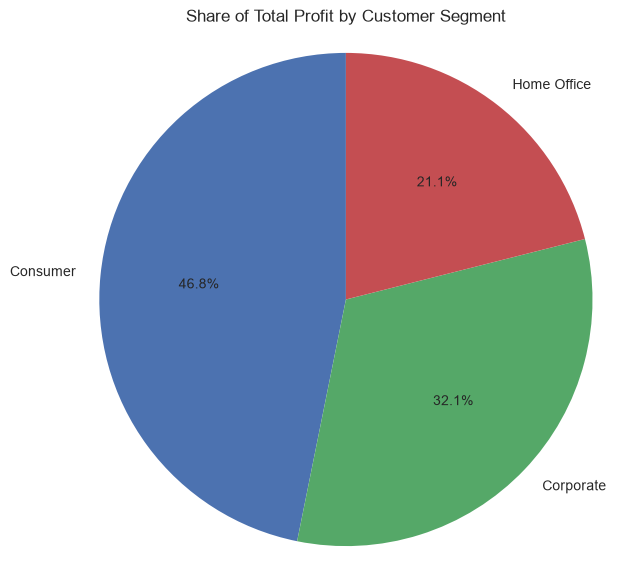

             Total_Sales  Total_Profit  Orders  Avg_Discount
Segment                                                     
Consumer     1161401.345    134119.209    2586         0.158
Corporate     706146.367     91979.134    1514         0.158
Home Office   429653.148     60298.678     909         0.147


In [55]:
segment_summary = df.groupby("Segment").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Orders=("Order ID", "nunique"),
    Avg_Discount=("Discount", "mean")
).sort_values("Total_Profit", ascending=False)

fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(segment_summary["Total_Profit"], labels=segment_summary.index, autopct="%1.1f%%",
       startangle=90, colors=["#4C72B0", "#55A868", "#C44E52"])
ax.set_title("Share of Total Profit by Customer Segment")
ax.axis("equal")
plt.show()

print(segment_summary.round(3))

### Practice Exercise
1. Group the data by `Ship Mode` and calculate total Sales, total Profit, and average `Shipping Days`
2. Create a bar chart comparing average `Shipping Days` across ship modes
3. Write one sentence: does faster shipping correlate with more or less profit per order?

In [56]:
# Student: write your Practice Exercise solution here

# Convert date columns to datetime format
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date'] = pd.to_datetime(df['Ship Date'])

# Calculate shipping days
df['Shipping Days'] = (
    df['Ship Date'] - df['Order Date']
).dt.days

# Group by Ship Mode
ship_summary = df.groupby('Ship Mode').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Average_Shipping_Days=('Shipping Days', 'mean')
)

# Display the summary
print(ship_summary.round(2))



                Total_Sales  Total_Profit  Average_Shipping_Days
Ship Mode                                                       
First Class       351428.42      48969.84                   2.18
Same Day          128363.12      15891.76                   0.04
Second Class      459193.57      57446.64                   3.24
Standard Class   1358215.74     164088.79                   5.01


## 7. Deep Dive: Does Discounting Actually Hurt Profit?

**Purpose:** This is the heart of the business problem. Leadership suspects heavy
discounting is eating into margins - let's actually TEST that with data instead
of guessing.

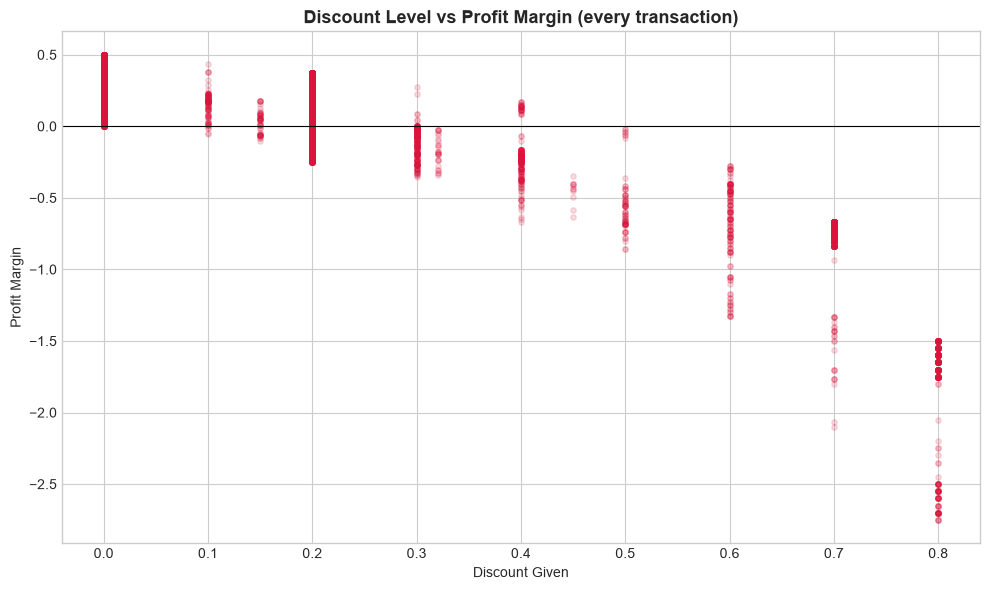

Correlation between Discount and Profit Margin: nan
(Closer to -1 = strong negative relationship, closer to 0 = no relationship)


In [57]:
# Scatter plot: Discount (x) vs Profit Margin (y) for every transaction
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(df["Discount"], df["Profit Margin"], alpha=0.15, color="crimson", s=15)

ax.set_title("Discount Level vs Profit Margin (every transaction)", fontsize=13, fontweight="bold")
ax.set_xlabel("Discount Given")
ax.set_ylabel("Profit Margin")
ax.axhline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

# Quantify the relationship with a correlation coefficient
# PURPOSE: np.corrcoef gives a number from -1 to 1 describing how strongly 2 variables move together
correlation = np.corrcoef(df["Discount"], df["Profit Margin"])[0, 1]
print(f"Correlation between Discount and Profit Margin: {correlation:.3f}")
print("(Closer to -1 = strong negative relationship, closer to 0 = no relationship)")

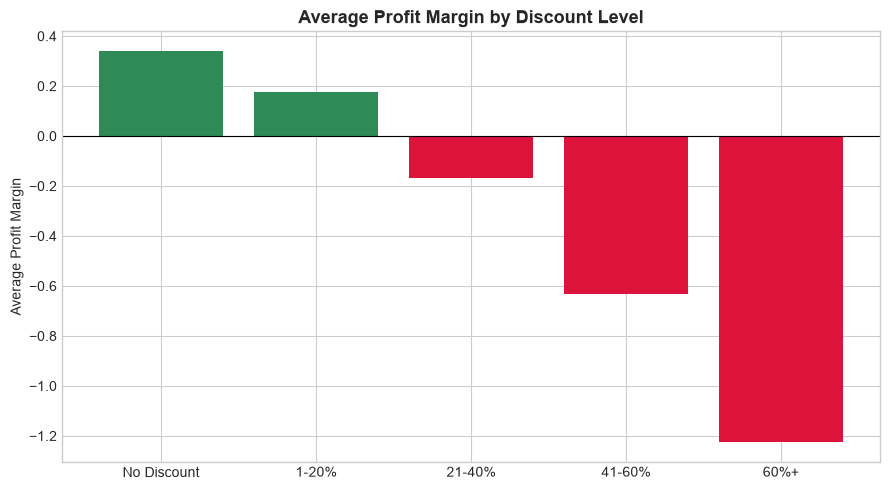

Discount Bucket
No Discount    0.340
1-20%          0.174
21-40%        -0.167
41-60%        -0.634
60%+          -1.225
Name: Profit Margin, dtype: float64

Insight: Once discounts exceed ~40%, the AVERAGE transaction becomes a LOSS.
This confirms leadership's suspicion -- deep discounting is a real profit problem.


In [58]:
# Break discount into buckets and compare average margin per bucket
# PURPOSE: makes the trend from the scatter plot much easier to read as a simple table/chart
bins = [-0.01, 0, 0.2, 0.4, 0.6, 1.0]
labels = ["No Discount", "1-20%", "21-40%", "41-60%", "60%+"]
df["Discount Bucket"] = pd.cut(df["Discount"], bins=bins, labels=labels)

discount_impact = df.groupby("Discount Bucket", observed=True)["Profit Margin"].mean()

fig, ax = plt.subplots(figsize=(9, 5))
colors = ["seagreen" if m > 0 else "crimson" for m in discount_impact]
ax.bar(discount_impact.index.astype(str), discount_impact.values, color=colors)
ax.set_title("Average Profit Margin by Discount Level", fontsize=13, fontweight="bold")
ax.set_ylabel("Average Profit Margin")
ax.axhline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

print(discount_impact.round(3))
print("\nInsight: Once discounts exceed ~40%, the AVERAGE transaction becomes a LOSS.")
print("This confirms leadership's suspicion -- deep discounting is a real profit problem.")

## 8. Insights & Recommendations (Executive Summary)

**Purpose:** This is the single most important section of any real analysis -
the part a busy manager will actually read. Numbers alone don't drive decisions;
clear, actionable conclusions do.

---

### Key Findings

1. **Seasonality is strong.** Sales consistently spike in November-December.
   -> *Recommendation:* Plan inventory and staffing ahead of Q4, and consider
   shifting marketing budget toward late-year campaigns.

2. **Technology is the profit engine; Furniture is a mixed bag.**
   Technology leads in both sales and profit, while Furniture's category-level
   profit is much thinner relative to its sales volume.
   -> *Recommendation:* Investigate Furniture's cost structure and pricing strategy.

3. **Specific sub-categories are actively losing money** (e.g. Tables, Bookcases in this dataset).
   -> *Recommendation:* Either renegotiate supplier costs for these sub-categories,
   reduce their discount eligibility, or reconsider carrying them at all.

4. **Discounting above ~40% turns transactions unprofitable on average.**
   The correlation between discount and profit margin is clearly negative.
   -> *Recommendation:* Cap standard discounts at a threshold below the point
   where margin turns negative, and require manager approval beyond that.

5. **Regions differ in efficiency, not just volume.** A region can have strong
   sales but a weaker margin than a smaller region.
   -> *Recommendation:* Don't reward regional teams on Sales alone - track
   Profit Margin as a core KPI per region.

---

### Why This Matters for a CV / Portfolio
This notebook demonstrates the full analyst workflow: **business question ->
data cleaning -> exploration -> visualization -> quantified insight ->
actionable recommendation.** That end-to-end story (not just "I know pandas
syntax") is what makes a project stand out to a hiring manager.

## 9. How to Extend This Project (for an even stronger CV piece)

Want to make this project even more impressive? Try adding:

1. **Time-series forecasting** - predict next quarter's sales using a simple
   moving average or `statsmodels`
2. **Customer segmentation (RFM analysis)** - classify customers by Recency,
   Frequency, and Monetary value of purchases
3. **A simple regression model** - predict Profit from Sales, Discount, and
   Category using `scikit-learn`
4. **An interactive dashboard** - rebuild the key charts in Plotly or Streamlit
   so a non-technical manager can explore the data themselves
5. **Publish it** - push this notebook to GitHub with a clear README, and add
   a short write-up to LinkedIn summarizing the 5 key findings above

### Final Practice Task
Pick ONE of the 5 findings above and go one level deeper: filter the data further
(e.g. "Furniture in the Central region only"), make a new chart, and write your
own recommendation in a markdown cell. This kind of self-directed deep-dive is
exactly what interviewers ask about - "tell me about a project" - so make sure
you can explain your OWN reasoning behind at least one insight, not just this notebook's.

Quarterly Sales:
Quarter
2015Q1     74447.7960
2015Q2     86538.7596
2015Q3    143633.2123
2015Q4    179627.7302
2016Q1     68851.7386
2016Q2     89124.1870
2016Q3    130259.5752
2016Q4    182297.0082
2017Q1     93237.1810
2017Q2    136082.3010
2017Q3    143787.3622
2017Q4    236098.7538
2018Q1    123144.8602
2018Q2    133764.3720
2018Q3    196251.9560
2018Q4    280054.0670
Freq: Q-DEC, Name: Sales, dtype: float64

Next Quarter Forecast:
2019Q1: 183,303.81


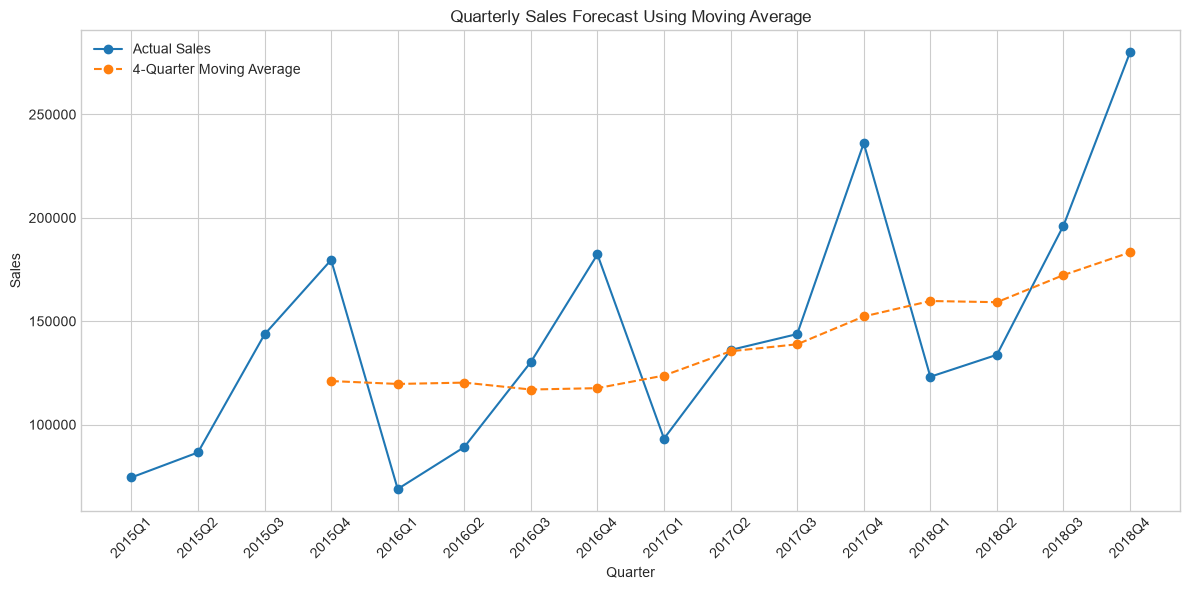

In [59]:
# Student: write your final deep-dive analysis here


import pandas as pd
import matplotlib.pyplot as plt

# Make sure Order Date is in datetime format
df['Order Date'] = pd.to_datetime(df['Order Date'])

# Create Quarter column
df['Quarter'] = df['Order Date'].dt.to_period('Q')

# Calculate total sales for each quarter
quarterly_sales = df.groupby('Quarter')['Sales'].sum()

print("Quarterly Sales:")
print(quarterly_sales)

# --------------------------------------------
# 4-Quarter Simple Moving Average
# --------------------------------------------

# Calculate moving average using the previous 4 quarters
moving_average = quarterly_sales.rolling(window=4).mean()

# Forecast for the next quarter
next_quarter_forecast = moving_average.iloc[-1]

# Get next quarter
next_quarter = quarterly_sales.index[-1] + 1

print("\nNext Quarter Forecast:")
print(f"{next_quarter}: {next_quarter_forecast:,.2f}")

# --------------------------------------------
# Plot Actual Sales + Moving Average
# --------------------------------------------

plt.figure(figsize=(12, 6))

plt.plot(
    quarterly_sales.index.astype(str),
    quarterly_sales.values,
    marker='o',
    label='Actual Sales'
)

plt.plot(
    moving_average.index.astype(str),
    moving_average.values,
    marker='o',
    linestyle='--',
    label='4-Quarter Moving Average'
)

plt.title('Quarterly Sales Forecast Using Moving Average')
plt.xlabel('Quarter')
plt.ylabel('Sales')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



RFM Analysis:
             Recency  Frequency  Monetary
Customer ID                              
AA-10315         185          5  5563.560
AA-10375          20          9  1056.390
AA-10480         260          4  1790.512
AA-10645          56          6  5086.935
AB-10015         416          3   886.156

Final Customer Segmentation:
             Recency  Frequency   Monetary  R_Score  F_Score  M_Score  \
Customer ID                                                             
AA-10315         185          5   5563.560        2        2        5   
AA-10375          20          9   1056.390        5        5        2   
AA-10480         260          4   1790.512        1        1        3   
AA-10645          56          6   5086.935        3        3        5   
AB-10015         416          3    886.156        1        1        1   
AB-10060          55          8   7755.620        3        4        5   
AB-10105          42         10  14473.571        4        5        5   
AB-10

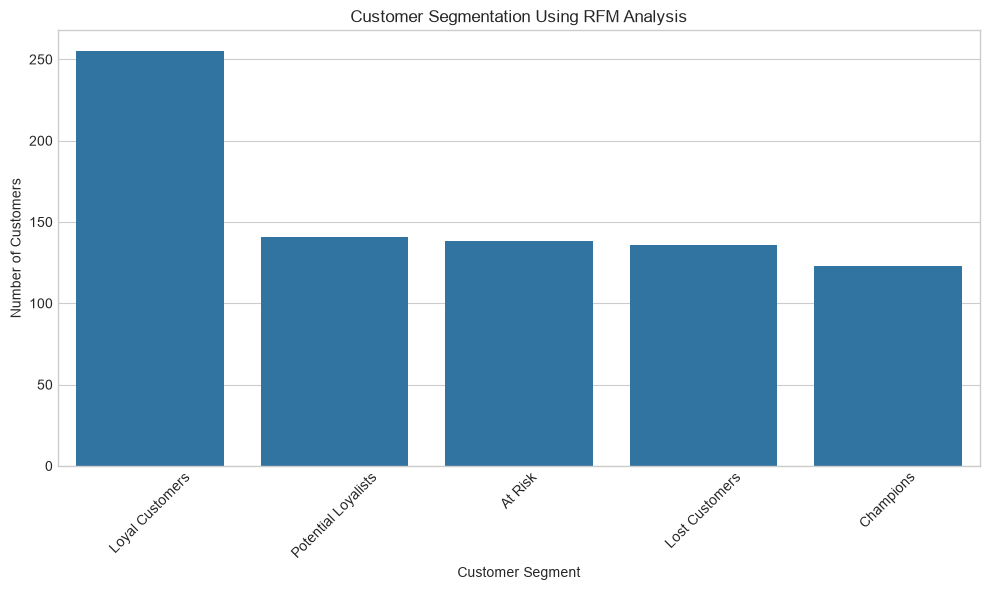

In [60]:
# ============================================
# CUSTOMER SEGMENTATION USING RFM ANALYSIS
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# --------------------------------------------
# 1. Make a copy of your existing dataframe
# --------------------------------------------

rfm_df = df.copy()

# --------------------------------------------
# 2. Convert Order Date to datetime
# --------------------------------------------

rfm_df['Order Date'] = pd.to_datetime(rfm_df['Order Date'])

# Remove rows without Customer ID
rfm_df = rfm_df.dropna(subset=['Customer ID'])

# --------------------------------------------
# 3. Set Analysis Date
# --------------------------------------------

# One day after the latest order in the dataset
analysis_date = rfm_df['Order Date'].max() + pd.Timedelta(days=1)

# --------------------------------------------
# 4. Calculate RFM
# --------------------------------------------

rfm = rfm_df.groupby('Customer ID').agg({
    'Order Date': lambda x: (analysis_date - x.max()).days,
    'Order ID': 'nunique',
    'Sales': 'sum'
})

# Rename columns
rfm.rename(columns={
    'Order Date': 'Recency',
    'Order ID': 'Frequency',
    'Sales': 'Monetary'
}, inplace=True)

# --------------------------------------------
# 5. Display RFM values
# --------------------------------------------

print("RFM Analysis:")
print(rfm.head())

# --------------------------------------------
# 6. Create RFM Scores
# --------------------------------------------

# Recency:
# Lower number of days = better customer
rfm['R_Score'] = pd.qcut(
    rfm['Recency'].rank(method='first'),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

# Frequency:
# Higher number of purchases = better
rfm['F_Score'] = pd.qcut(
    rfm['Frequency'].rank(method='first'),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Monetary:
# Higher spending = better
rfm['M_Score'] = pd.qcut(
    rfm['Monetary'].rank(method='first'),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# --------------------------------------------
# 7. Calculate Overall RFM Score
# --------------------------------------------

rfm['RFM_Score'] = (
    rfm['R_Score'] +
    rfm['F_Score'] +
    rfm['M_Score']
)

# --------------------------------------------
# 8. Customer Segmentation
# --------------------------------------------

def segment_customer(row):

    if row['RFM_Score'] >= 13:
        return 'Champions'

    elif row['RFM_Score'] >= 10:
        return 'Loyal Customers'

    elif row['RFM_Score'] >= 8:
        return 'Potential Loyalists'

    elif row['RFM_Score'] >= 6:
        return 'At Risk'

    else:
        return 'Lost Customers'


rfm['Segment'] = rfm.apply(segment_customer, axis=1)

# --------------------------------------------
# 9. Display Final RFM Table
# --------------------------------------------

print("\nFinal Customer Segmentation:")
print(
    rfm[
        [
            'Recency',
            'Frequency',
            'Monetary',
            'R_Score',
            'F_Score',
            'M_Score',
            'RFM_Score',
            'Segment'
        ]
    ].head(20)
)

# --------------------------------------------
# 10. Count Customers in Each Segment
# --------------------------------------------

segment_counts = rfm['Segment'].value_counts()

print("\nCustomer Segment Counts:")
print(segment_counts)

# --------------------------------------------
# 11. Bar Chart
# --------------------------------------------

plt.figure(figsize=(10, 6))

sns.barplot(
    x=segment_counts.index,
    y=segment_counts.values
)

plt.title('Customer Segmentation Using RFM Analysis')
plt.xlabel('Customer Segment')
plt.ylabel('Number of Customers')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


Regression Dataset:
      Sales  Discount         Category    Profit
0  261.9600      0.00        Furniture   41.9136
1  731.9400      0.00        Furniture  219.5820
2   14.6200      0.00  Office Supplies    6.8714
3  957.5775      0.45        Furniture -383.0310
4   22.3680      0.20  Office Supplies    2.5164

REGRESSION MODEL RESULTS
Mean Absolute Error (MAE): 68.33
Mean Squared Error (MSE): 83665.91
Root Mean Squared Error (RMSE): 289.25
R² Score: -0.7256

Actual vs Predicted Profit:
    Actual Profit  Predicted Profit
0         21.1428        127.974784
1         11.4600        -10.000607
2         17.1580        -32.318134
3        -15.1470        -48.434015
4         -6.4233        -38.486048
5          8.6744          6.349054
6        -73.7061          6.333447
7          8.6900         26.188451
8        -15.0800       -116.775274
9         17.9080         -0.849990
10       -17.2854       -140.573234
11        31.5372        -21.947783
12         1.4602         27.099324
13

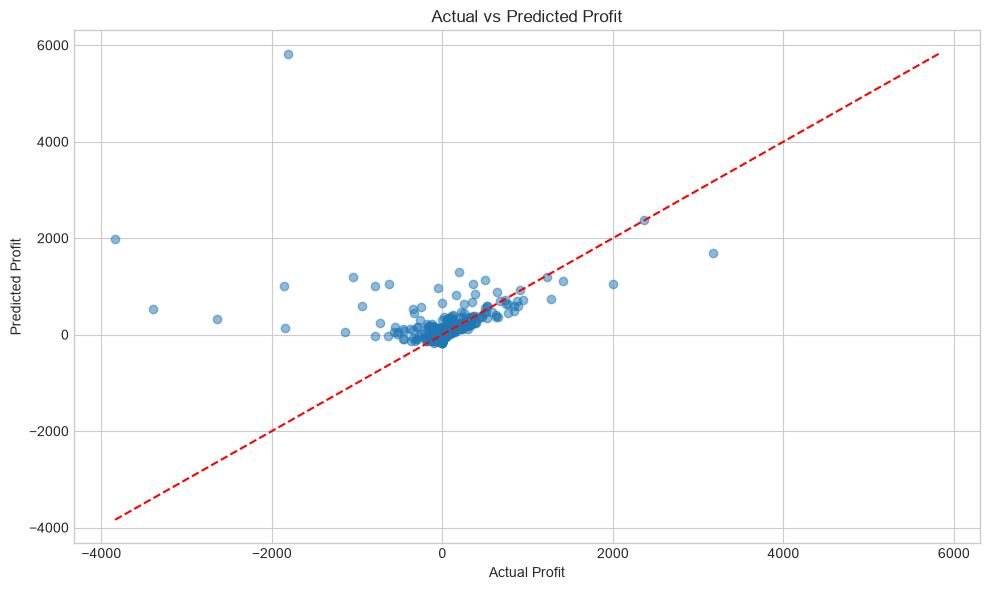

In [61]:
# ============================================
# SIMPLE REGRESSION MODEL
# Predict Profit from Sales, Discount & Category
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# --------------------------------------------
# 1. Select Required Columns
# --------------------------------------------

reg_df = df[['Sales', 'Discount', 'Category', 'Profit']].copy()

# Remove missing values
reg_df = reg_df.dropna()

print("Regression Dataset:")
print(reg_df.head())


# --------------------------------------------
# 2. Define Features and Target
# --------------------------------------------

X = reg_df[['Sales', 'Discount', 'Category']]
y = reg_df['Profit']


# --------------------------------------------
# 3. Encode Category
# --------------------------------------------

# Category is text, so we convert it into numerical
# values using One-Hot Encoding.

preprocessor = ColumnTransformer(
    transformers=[
        ('category', OneHotEncoder(handle_unknown='ignore'), ['Category'])
    ],
    remainder='passthrough'
)


# --------------------------------------------
# 4. Train-Test Split
# --------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)


# --------------------------------------------
# 5. Transform Category
# --------------------------------------------

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)


# --------------------------------------------
# 6. Create Linear Regression Model
# --------------------------------------------

model = LinearRegression()

model.fit(X_train_processed, y_train)


# --------------------------------------------
# 7. Make Predictions
# --------------------------------------------

y_pred = model.predict(X_test_processed)


# --------------------------------------------
# 8. Evaluate Model
# --------------------------------------------

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)


print("\n================================")
print("REGRESSION MODEL RESULTS")
print("================================")

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R² Score: {r2:.4f}")


# --------------------------------------------
# 9. Compare Actual vs Predicted Profit
# --------------------------------------------

results = pd.DataFrame({
    'Actual Profit': y_test.values,
    'Predicted Profit': y_pred
})

print("\nActual vs Predicted Profit:")
print(results.head(20))


# --------------------------------------------
# 10. Visualize Actual vs Predicted
# --------------------------------------------

plt.figure(figsize=(10, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.5
)

# Perfect prediction line
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    color='red',
    linestyle='--'
)

plt.xlabel('Actual Profit')
plt.ylabel('Predicted Profit')

plt.title('Actual vs Predicted Profit')

plt.grid(True)
plt.tight_layout()
plt.show()


---
## Project Complete

You've now built a full, realistic, end-to-end data analysis project using
**NumPy + Pandas + Matplotlib** together - exactly how they're used in real jobs.

**To use this for your CV/portfolio:**
- Upload this notebook (and `superstore.csv`) to a GitHub repository
- Write a short README summarizing the business problem and your top findings
- Link it from your resume/LinkedIn as "Retail Sales Performance Analysis"

*Good luck - this is real, defensible, portfolio-quality work.*